# 02 · Modelos lineares para prever a progressão da diabetes

**Pergunta:** com as medições iniciais, quanto se consegue prever a progressão da doença um ano depois?

**Método:**
1. Separar 20% dos dados para teste e não lhes tocar até ao fim.
2. Comparar modelos no treino com validação cruzada (5 divisões): uma linha de base (`DummyRegressor`), regressão linear com vários pré-processamentos e transformação do alvo.
3. Ajustar Ridge, Lasso e ElasticNet com `GridSearchCV`.
4. Escolher o modelo pelo RMSE médio e avaliá-lo uma única vez no teste.

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import learning_curve, train_test_split, KFold
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, QuantileTransformer, StandardScaler

from src.config import DADOS_TRATADOS, METRICAS_TESTE, MODELO_FINAL, PASTA_IMAGENS, RESULTADOS_CV, SEMENTE
from src.graficos import aplicar_estilo, comparar_metricas, coeficientes, residuos, CORES
from src.modelos import comparar_modelos, construir_modelo, grid_search, resumo

aplicar_estilo()

In [2]:
df = pd.read_csv(DADOS_TRATADOS)
df["sexo"] = df["sexo"].astype("category")

X = df.drop(columns="progressao")
y = df["progressao"]

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEMENTE)
print(f"Treino: {len(X_treino)} · Teste: {len(X_teste)}")

numericas = X.select_dtypes("number").columns.tolist()
categoricas = ["sexo"]

Treino: 353 · Teste: 89


## Pré-processamentos a comparar

In [3]:
padronizar = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(drop="if_binary"), categoricas),
])

power = ColumnTransformer([
    ("num", PowerTransformer(method="yeo-johnson"), numericas),
    ("cat", OneHotEncoder(drop="if_binary"), categoricas),
])

alvo_normal = QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEMENTE)

modelos = {
    "Dummy (média)": construir_modelo(DummyRegressor(strategy="mean")),
    "Linear": construir_modelo(LinearRegression(), padronizar),
    "Linear + Yeo-Johnson": construir_modelo(LinearRegression(), power),
    "Linear + alvo transformado": construir_modelo(LinearRegression(), padronizar, alvo_normal),
    "Linear + Yeo-Johnson + alvo": construir_modelo(LinearRegression(), power, alvo_normal),
}

## Comparação com validação cruzada

In [4]:
resultados = comparar_modelos(modelos, X_treino, y_treino, semente=SEMENTE)
resumo(resultados).round(2)

MAE         RMSE          R2      
                              mean   std   mean   std  mean   std
modelo                                                           
Linear                       45.05  1.98  55.39  2.64  0.48  0.05
Linear + Yeo-Johnson         45.49  2.80  55.91  2.97  0.47  0.04
Linear + Yeo-Johnson + alvo  45.32  1.99  56.46  2.29  0.46  0.07
Linear + alvo transformado   45.26  1.42  56.69  1.76  0.45  0.09
Dummy (média)                66.87  6.30  78.13  6.30 -0.03  0.03

## Regularização: Ridge, Lasso e ElasticNet

As variáveis do sangue são muito correlacionadas entre si; a regularização reduz os coeficientes e pode estabilizar o modelo.

In [5]:
alfas = np.logspace(-3, 2, 30)

busca = {
    "Ridge": grid_search(construir_modelo(Ridge(), padronizar),
                         {"regressor__alpha": alfas}, X_treino, y_treino, semente=SEMENTE),
    "Lasso": grid_search(construir_modelo(Lasso(max_iter=50_000), padronizar),
                         {"regressor__alpha": alfas}, X_treino, y_treino, semente=SEMENTE),
    "ElasticNet": grid_search(construir_modelo(ElasticNet(max_iter=50_000), padronizar),
                              {"regressor__alpha": alfas, "regressor__l1_ratio": [0.1, 0.5, 0.9]},
                              X_treino, y_treino, semente=SEMENTE),
}
for nome, gs in busca.items():
    print(f"{nome:<11} melhor: {gs.best_params_}  RMSE CV: {-gs.best_score_:.2f}")

Ridge       melhor: {'regressor__alpha': np.float64(0.8531678524172814)}  RMSE CV: 55.37
Lasso       melhor: {'regressor__alpha': np.float64(0.1743328822199989)}  RMSE CV: 55.36
ElasticNet  melhor: {'regressor__alpha': np.float64(0.02395026619987486), 'regressor__l1_ratio': 0.9}  RMSE CV: 55.37


In [6]:
modelos_reg = {f"{nome} (ajustado)": gs.best_estimator_ for nome, gs in busca.items()}
resultados = pd.concat([resultados, comparar_modelos(modelos_reg, X_treino, y_treino, semente=SEMENTE)],
                       ignore_index=True)
resultados.to_csv(RESULTADOS_CV, index=False)

tabela = resumo(resultados).round(2)
tabela

MAE         RMSE          R2      
                              mean   std   mean   std  mean   std
modelo                                                           
Lasso (ajustado)             44.96  2.10  55.36  2.61  0.48  0.04
ElasticNet (ajustado)        45.00  2.03  55.37  2.64  0.48  0.04
Ridge (ajustado)             45.01  2.02  55.37  2.64  0.48  0.05
Linear                       45.05  1.98  55.39  2.64  0.48  0.05
Linear + Yeo-Johnson         45.49  2.80  55.91  2.97  0.47  0.04
Linear + Yeo-Johnson + alvo  45.32  1.99  56.46  2.29  0.46  0.07
Linear + alvo transformado   45.26  1.42  56.69  1.76  0.45  0.09
Dummy (média)                66.87  6.30  78.13  6.30 -0.03  0.03

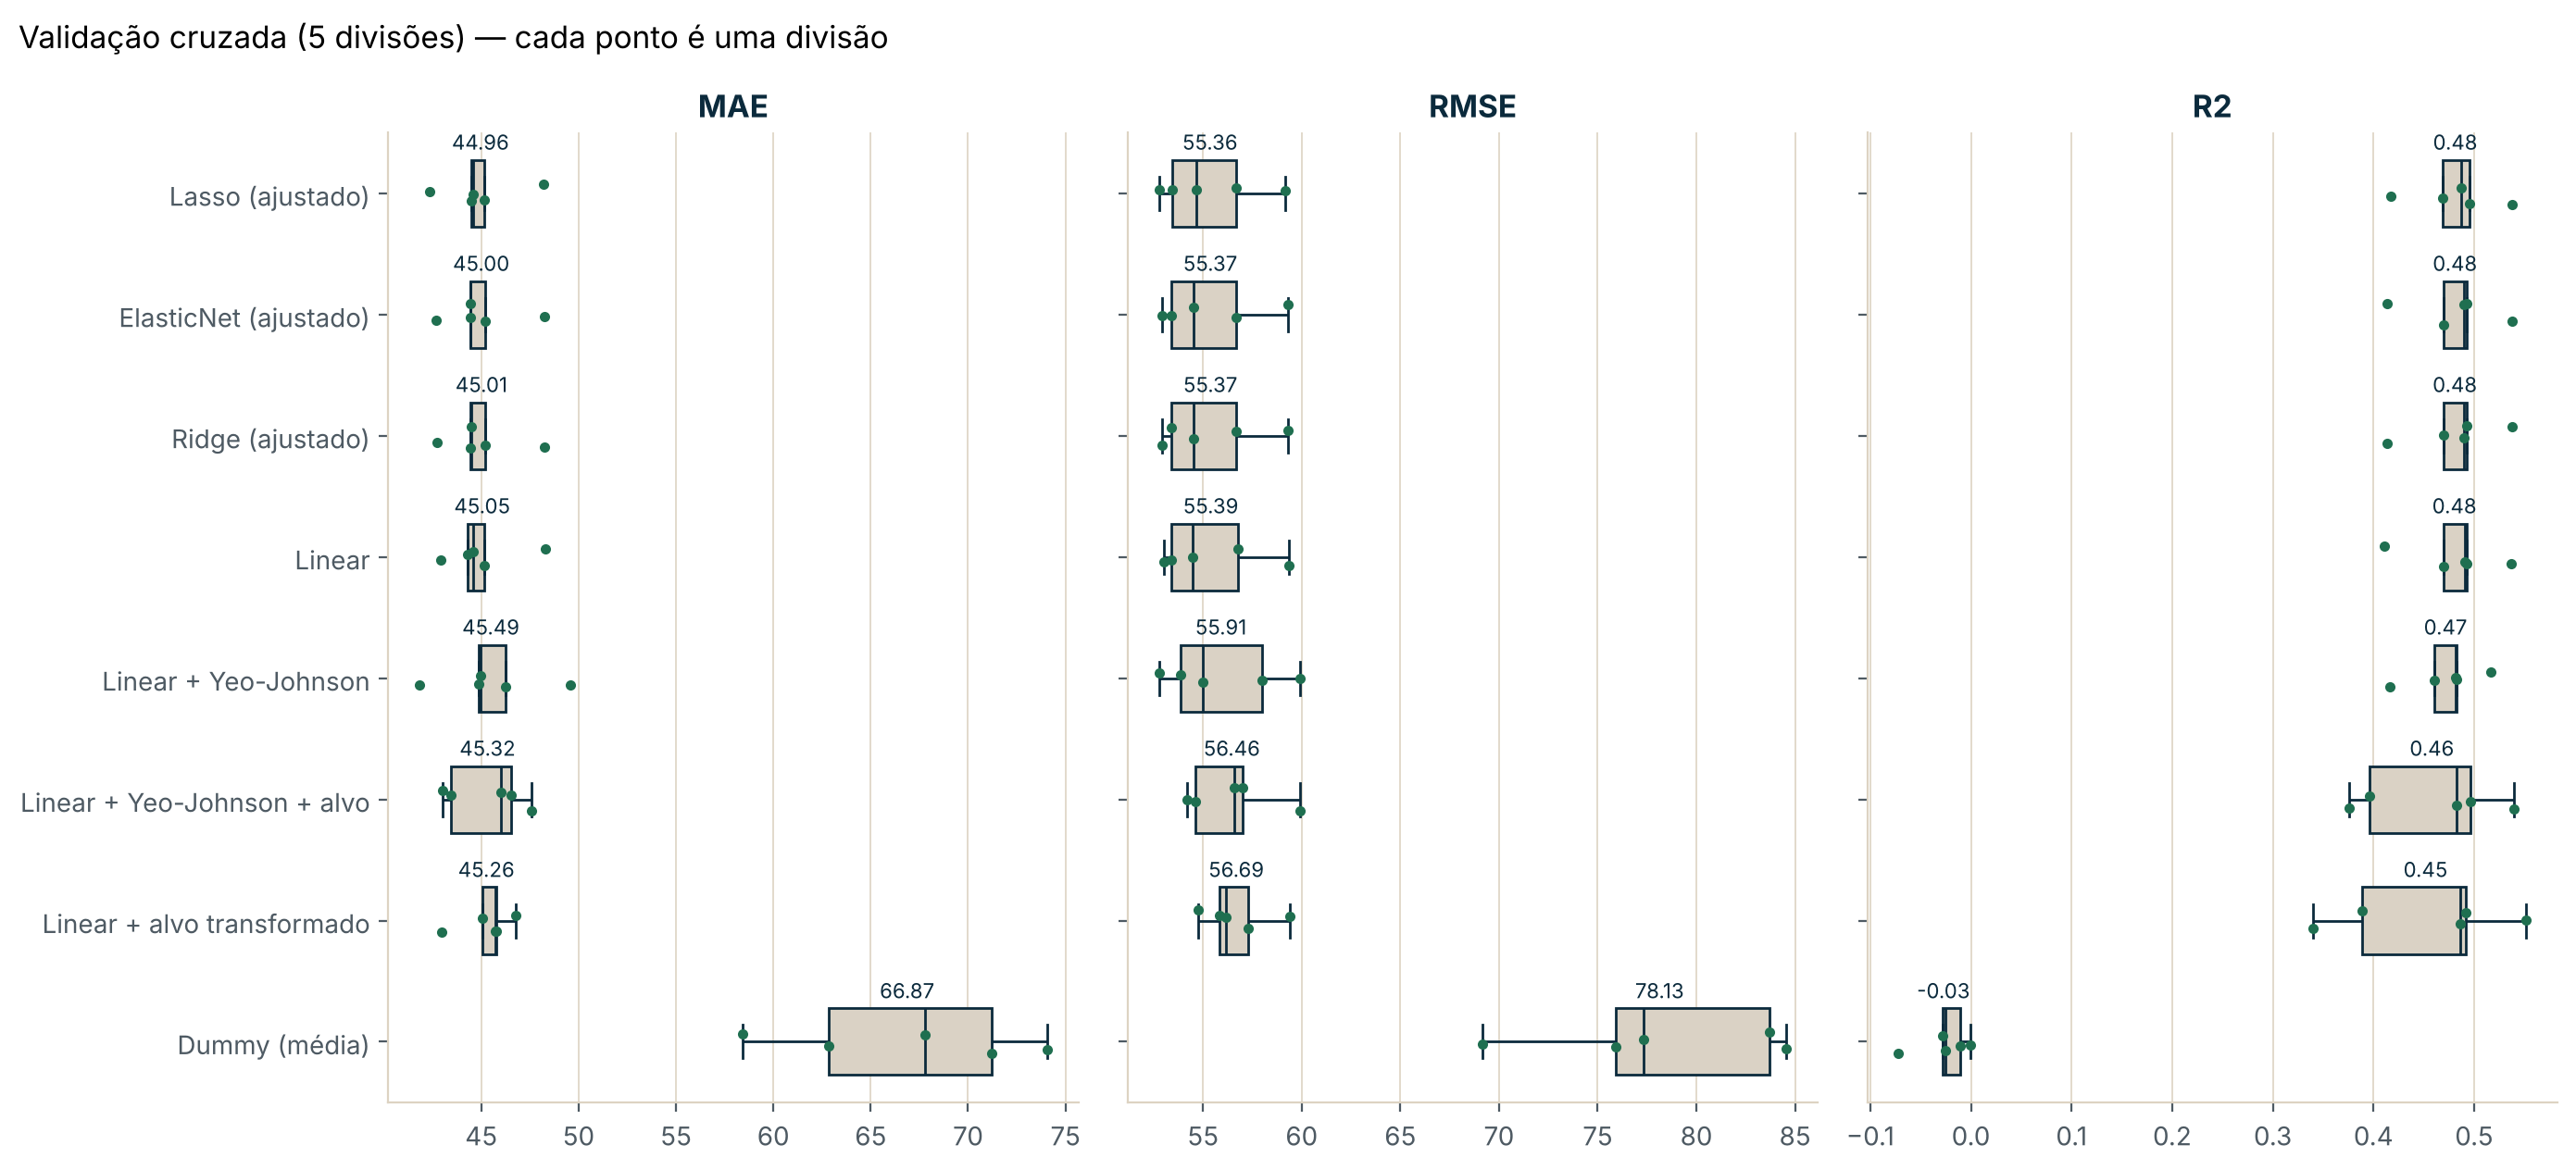

In [7]:
comparar_metricas(resultados, ficheiro=PASTA_IMAGENS / "02_comparacao_modelos.png");

**Leitura:** todos os modelos lineares batem a linha de base com folga (o `Dummy` tem R² ≈ 0). Entre eles, as diferenças são pequenas e menores do que a variação entre divisões: a escolha do pré-processamento ou da regularização quase não muda o resultado nesta base.

## Modelo escolhido

O critério é o menor RMSE médio na validação cruzada.

In [8]:
escolhido = tabela.index[0]
todos = {**modelos, **modelos_reg}
modelo = todos[escolhido]
print("Modelo escolhido:", escolhido)
modelo.fit(X_treino, y_treino)

Modelo escolhido: Lasso (ajustado)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessamento', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['idade','sexo','imc',...,'colesterol_hdl','triglicerideos_log','glicose']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset

## Coeficientes

Como as variáveis numéricas estão padronizadas, cada coeficiente é o efeito de aumentar a variável em um desvio-padrão, mantendo as outras fixas.

,coeficiente
triglicerideos_log,28.27
colesterol_total,-26.09
imc,26.01
sexo_2,-21.83
pressao_media,16.52
colesterol_hdl,10.57
ldl,10.33
glicose,2.38
idade,1.64
hdl,-0.00


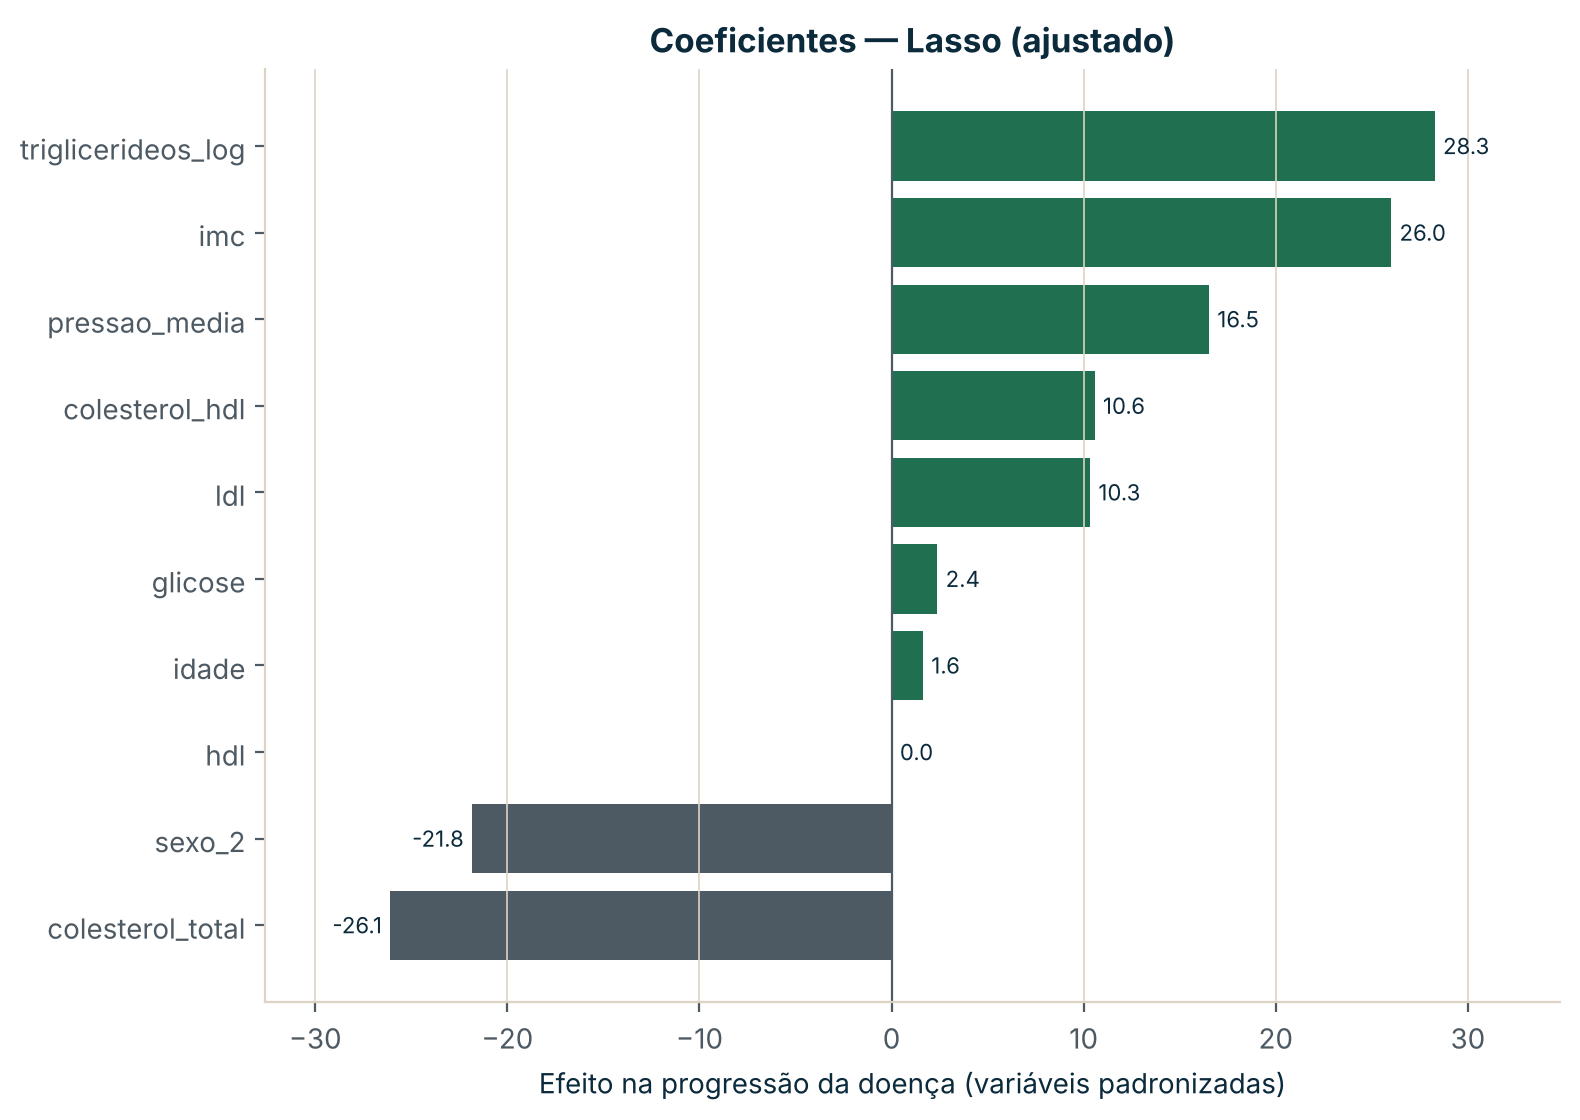

In [9]:
pipe = modelo.regressor_ if hasattr(modelo, "regressor_") else modelo
nomes = pipe.named_steps["preprocessamento"].get_feature_names_out()
nomes = [n.split("__")[1] for n in nomes]
coef = pd.DataFrame({"coeficiente": pipe.named_steps["regressor"].coef_}, index=nomes)
if hasattr(modelo, "regressor_"):
    print("Atenção: o alvo foi transformado; os coeficientes estão na escala transformada.")
coeficientes(coef, titulo=f"Coeficientes — {escolhido}", ficheiro=PASTA_IMAGENS / "02_coeficientes.png");
coef.sort_values("coeficiente", key=abs, ascending=False).round(2)

**Leitura:** os maiores efeitos positivos vêm dos triglicerídeos, do IMC e da pressão média, de acordo com a análise exploratória. O colesterol total e o LDL aparecem com sinais opostos: é o efeito da colinearidade entre eles, por isso não se devem interpretar isoladamente. O Lasso pôs o HDL a zero porque a sua informação já está no rácio colesterol/HDL. O `sexo_2` é a diferença média entre os dois grupos, não um efeito padronizado.

## Curva de aprendizagem

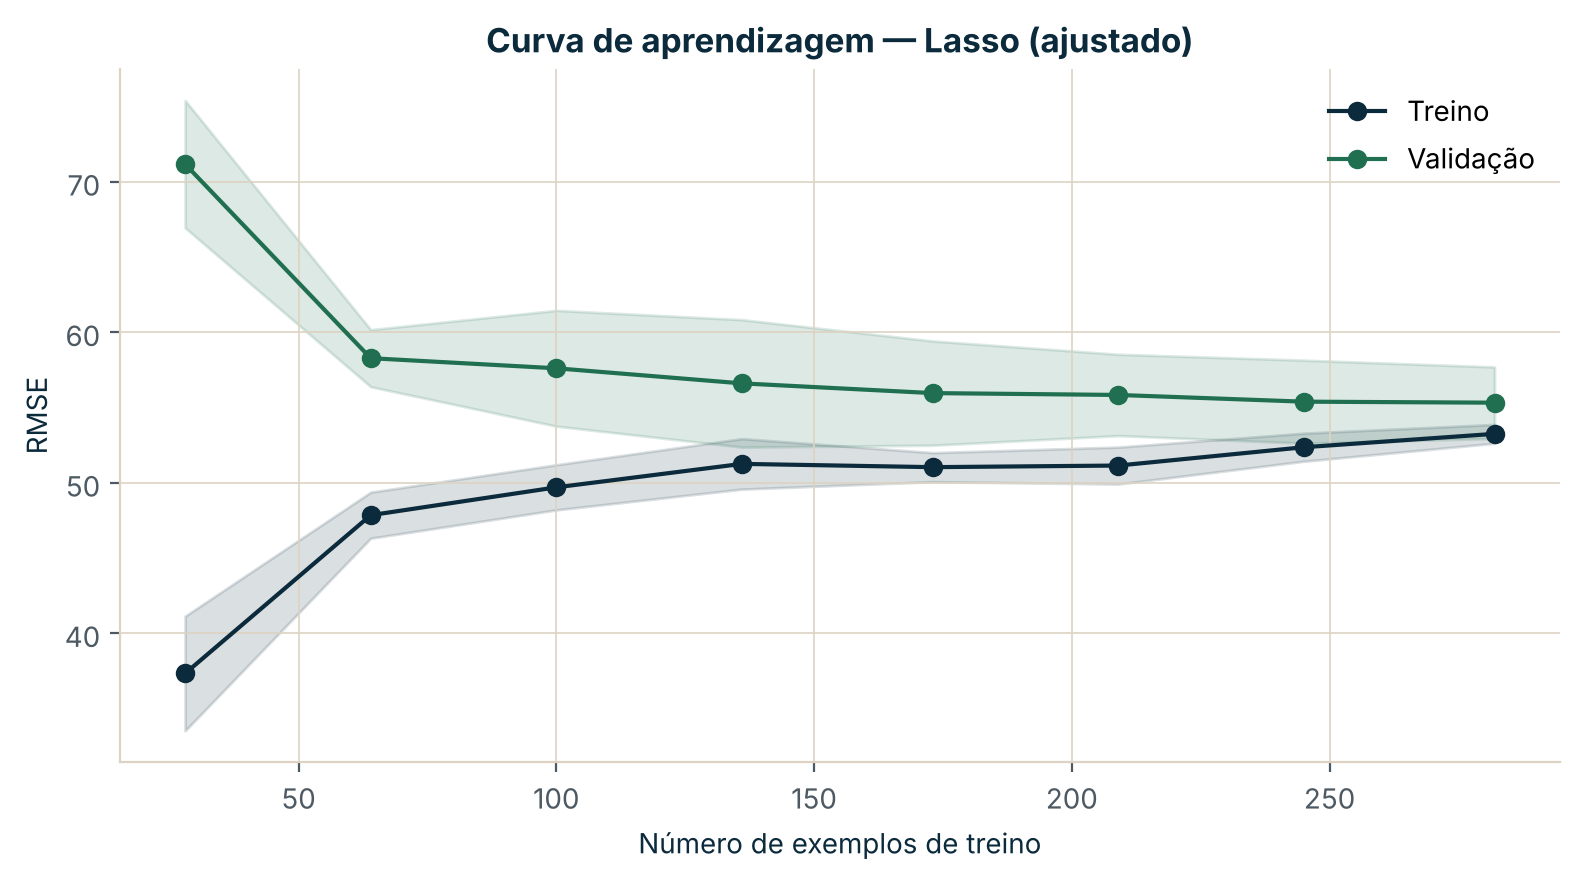

In [10]:
tamanhos, sc_treino, sc_val = learning_curve(
    modelo, X_treino, y_treino, cv=KFold(5, shuffle=True, random_state=SEMENTE),
    scoring="neg_root_mean_squared_error", train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)

fig, ax = plt.subplots(figsize=(8, 4.5))
for sc, nome, cor in [(sc_treino, "Treino", CORES["navy"]), (sc_val, "Validação", CORES["verde"])]:
    media, dp = -sc.mean(axis=1), sc.std(axis=1)
    ax.plot(tamanhos, media, marker="o", color=cor, label=nome)
    ax.fill_between(tamanhos, media - dp, media + dp, color=cor, alpha=0.15)
ax.set(xlabel="Número de exemplos de treino", ylabel="RMSE", title=f"Curva de aprendizagem — {escolhido}")
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_IMAGENS / "02_curva_aprendizagem.png")

As duas curvas aproximam-se e estabilizam: mais dados do mesmo tipo pouco ajudariam. O limite está na informação que estas 10 variáveis contêm, não no tamanho da base.

## Avaliação final no teste

Única vez que o conjunto de teste é usado.

In [11]:
y_prev = modelo.predict(X_teste)
metricas = pd.DataFrame({
    "modelo": [escolhido],
    "MAE": [mean_absolute_error(y_teste, y_prev)],
    "RMSE": [root_mean_squared_error(y_teste, y_prev)],
    "R2": [r2_score(y_teste, y_prev)],
}).round(2)
metricas.to_csv(METRICAS_TESTE, index=False)
metricas

,modelo,MAE,RMSE,R2
0,Lasso (ajustado),42.84,53.67,0.46


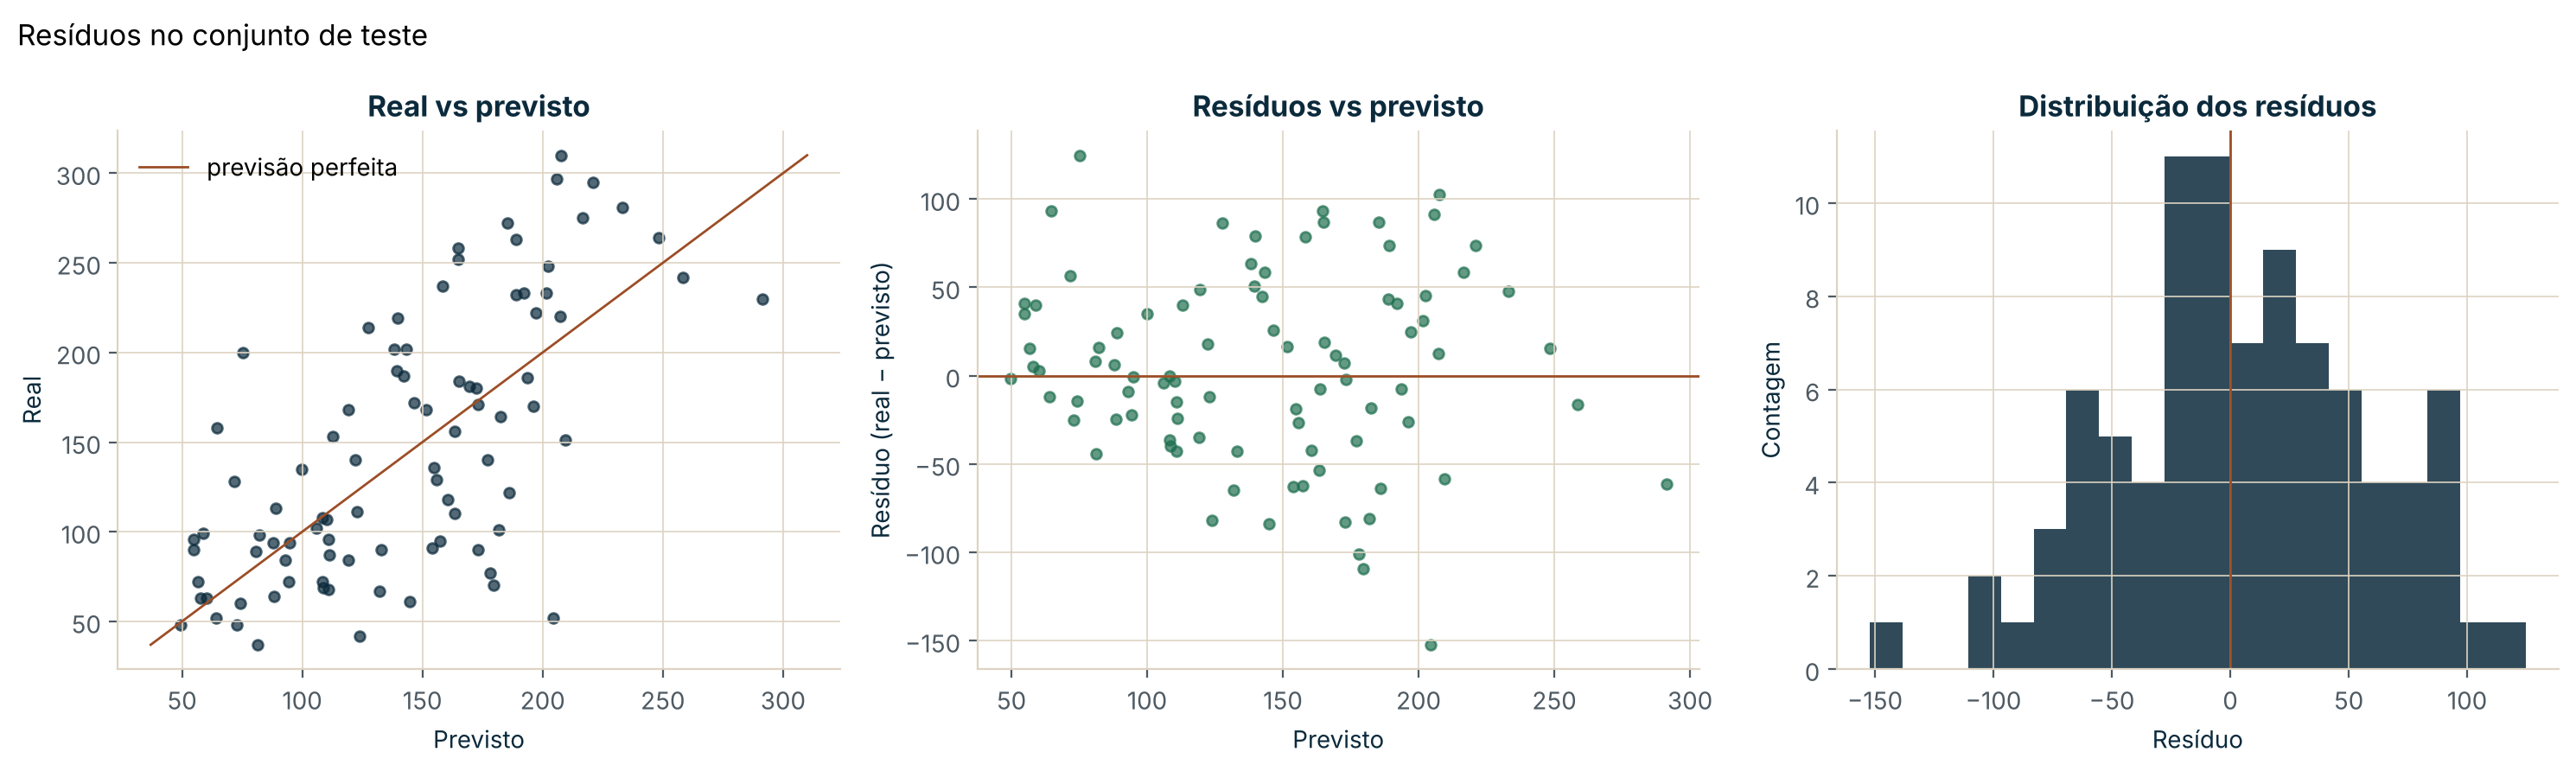

In [12]:
residuos(y_teste, y_prev, ficheiro=PASTA_IMAGENS / "02_residuos.png");

**Leitura:** os resíduos não mostram um padrão forte, mas o modelo subestima as progressões mais altas e sobrestima as mais baixas (os pontos afastam-se da diagonal nos extremos). É o comportamento típico de um modelo linear com R² perto de 0,5: explica cerca de metade da variação.

## Guardar o modelo

In [13]:
joblib.dump(modelo, MODELO_FINAL)
print(MODELO_FINAL.name, "guardado")

modelo_final.joblib guardado


## Conclusões

- Os modelos lineares explicam cerca de metade da variação da progressão (ver R² acima); a linha de base não explica nada.
- Pré-processamento, transformação do alvo e regularização mudam pouco o resultado: as diferenças ficam dentro da variação entre divisões da validação cruzada.
- **Limitações:** 442 doentes de um único estudo; o significado da codificação do sexo não é conhecido; o modelo é associativo, não causal; com variáveis tão correlacionadas, os coeficientes individuais não devem ser lidos isoladamente.